# Lab 1. Intro to Behavioral TV Data
Name: Nazar Harbarchuk | Group: KM-41


## Setup

In [10]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

# Colab and Kaggle

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

## Task 1.1 — Panel and universe

In [11]:
# Calculations for programs
num_telecasts = programs['telecast_id'].nunique()
num_programs = programs['program_name'].nunique()
num_networks = programs['network_code'].nunique()

# Calculations for panel sizes
households_in_panel = daily_weights[daily_weights['resp_type'] == 'H']['respondent_id'].nunique()
persons_in_panel = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'].nunique()

# Calculations for in-tab on average day
daily_hh = daily_weights[daily_weights['resp_type'] == 'H'].groupby('broadcast_date')['respondent_id'].nunique()
daily_persons = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].groupby('broadcast_date')['respondent_id'].nunique()

avg_hh_in_tab = round(daily_hh.mean())
avg_persons_in_tab = round(daily_persons.mean())

# Calculations for projections (in Millions)
daily_projected_hh = daily_weights[daily_weights['resp_type'] == 'H'].groupby('broadcast_date')['weight'].sum()
daily_projected_persons = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].groupby('broadcast_date')['weight'].sum()

avg_projected_hh_m = round(daily_projected_hh.mean() / 1_000_000, 2)
avg_projected_persons_m = round(daily_projected_persons.mean() / 1_000_000, 2)

In [12]:
print("Telecasts:", num_telecasts)
print("Programs:", num_programs)
print("Networks:", num_networks)
print("Households in panel:", households_in_panel)
print("Persons in panel:", persons_in_panel)
print("Households in-tab, average day:", avg_hh_in_tab)
print("Persons in-tab, average day:", avg_persons_in_tab)
print("US TV households represented, average day (M):", avg_projected_hh_m)
print("US persons represented, average day (M):", avg_projected_persons_m)

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9269
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28


**Answer:** `viewer_attributes` lists more respondents because it includes all individuals registered in the panel, whereas `daily_weights` only includes those who were "in-tab" (successfully measured their viewing) on any given day. If a panel member's meter failed or they were away for the entire month, they remain in the attributes table but will not appear in the daily weights.

## Task 1.2 — Average audience by hour of day

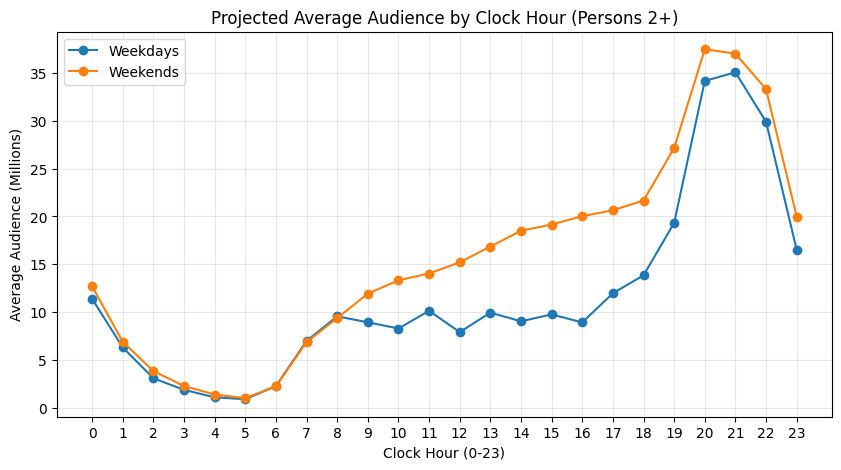

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [13]:
# Filter for persons only (R and L)
person_viewings = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

# A session from 20:50 to 21:20 adds 10 minutes to hour 20 and 20 minutes to hour 21.
# Expand sessions minute by minute to correctly attribute viewing time to clock hours.
expanded_viewings = []
for _, row in person_viewings.iterrows():
    current_time = row['start_ts']
    end_time = row['end_ts']
    weight = row['weight']

    while current_time < end_time:
        if current_time.hour < 6:
            bd_date = (current_time - pd.Timedelta(days=1)).date()
        else:
            bd_date = current_time.date()

        expanded_viewings.append({
            'clock_hour': current_time.hour,
            'broadcast_date': bd_date,
            'weight': weight
        })
        current_time += pd.Timedelta(minutes=1)

df_expanded = pd.DataFrame(expanded_viewings)
df_expanded['broadcast_date'] = pd.to_datetime(df_expanded['broadcast_date'])
df_expanded['is_weekend'] = df_expanded['broadcast_date'].dt.dayofweek >= 5

# October 2024 (starts on Tuesday): 8 weekend days, 23 weekdays
num_weekdays = 23
num_weekends = 8

hourly_weights = df_expanded.groupby(['clock_hour', 'is_weekend'])['weight'].sum().reset_index()
hourly_weights['avg_audience_m'] = 0.0

weekday_mask = ~hourly_weights['is_weekend']
hourly_weights.loc[weekday_mask, 'avg_audience_m'] = (hourly_weights.loc[weekday_mask, 'weight'] / 60 / num_weekdays) / 1_000_000

weekend_mask = hourly_weights['is_weekend']
hourly_weights.loc[weekend_mask, 'avg_audience_m'] = (hourly_weights.loc[weekend_mask, 'weight'] / 60 / num_weekends) / 1_000_000

weekdays_data = hourly_weights[~hourly_weights['is_weekend']].sort_values('clock_hour')
weekends_data = hourly_weights[hourly_weights['is_weekend']].sort_values('clock_hour')

# Plot
plt.figure(figsize=(10, 5))
plt.plot(weekdays_data['clock_hour'], weekdays_data['avg_audience_m'], label='Weekdays', marker='o')
plt.plot(weekends_data['clock_hour'], weekends_data['avg_audience_m'], label='Weekends', marker='o')
plt.title('Projected Average Audience by Clock Hour (Persons 2+)')
plt.xlabel('Clock Hour (0-23)')
plt.ylabel('Average Audience (Millions)')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

peak_hour_weekdays = weekdays_data.loc[weekdays_data['avg_audience_m'].idxmax(), 'clock_hour']
peak_hour_weekends = weekends_data.loc[weekends_data['avg_audience_m'].idxmax(), 'clock_hour']

print("Peak hour, weekdays:", peak_hour_weekdays)
print("Peak hour, weekends:", peak_hour_weekends)

**Answer:** The weekend pattern differs from weekdays mostly during daytime hours. While weekday viewership stays low until the late afternoon/early evening (when people return from work or school), weekend viewership rises much earlier in the morning and remains consistently higher throughout the entire day.

## Task 1.3 — Session length

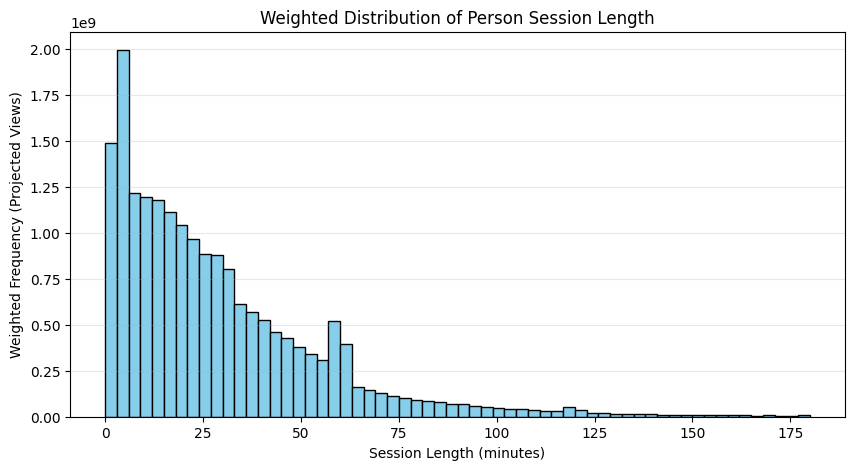

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [14]:
# Filter for persons only (R and L)
person_sessions = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

# Calculate session length in minutes
person_sessions['duration_min'] = (person_sessions['end_ts'] - person_sessions['start_ts']).dt.total_seconds() / 60

# Calculate weighted mean
weighted_mean_session = (person_sessions['duration_min'] * person_sessions['weight']).sum() / person_sessions['weight'].sum()

# Calculate weighted median
sorted_sessions = person_sessions.sort_values('duration_min')
cumulative_weight = sorted_sessions['weight'].cumsum()
total_weight = sorted_sessions['weight'].sum()
median_idx = (cumulative_weight >= total_weight / 2).idxmax()
weighted_median_session = sorted_sessions.loc[median_idx, 'duration_min']

# Plot weighted distribution of session length
# Limiting range to 180 minutes for better visibility of the main distribution
plt.figure(figsize=(10, 5))
plt.hist(person_sessions['duration_min'], weights=person_sessions['weight'], bins=60, range=(0, 180), color='skyblue', edgecolor='black')
plt.title('Weighted Distribution of Person Session Length')
plt.xlabel('Session Length (minutes)')
plt.ylabel('Weighted Frequency (Projected Views)')
plt.grid(axis='y', alpha=0.3)
plt.show()

print("Session length, weighted mean (min):", round(weighted_mean_session, 1))
print("Session length, weighted median (min):", round(weighted_median_session, 1))

**Answer:** The weighted mean and median differ significantly because the distribution of session lengths is heavily right-skewed. While the majority of viewing sessions are relatively short, there is a long tail of very long sessions (e.g., someone leaving the TV on for several hours), which artificially inflates the mean. For a client deck, I would report the median, as it is robust against these extreme outliers and provides a much more accurate representation of a "typical" viewer's session length.

## Task 2 — Program reach curve

Date            | HH Rating %     | P2+ Rating %    | Proj Aud (M)   
-----------------------------------------------------------------
2024-10-01      | 17.55           | 8.68            | 27.54          
2024-10-02      | 17.71           | 8.63            | 27.37          
2024-10-03      | 16.78           | 8.47            | 26.86          
2024-10-04      | 17.04           | 8.25            | 26.18          
2024-10-07      | 17.24           | 8.45            | 26.80          
2024-10-08      | 16.70           | 8.34            | 26.45          
2024-10-09      | 17.02           | 8.43            | 26.75          
2024-10-10      | 18.03           | 8.72            | 27.67          
2024-10-11      | 16.05           | 8.03            | 25.47          
2024-10-14      | 20.95           | 10.48           | 33.25          
2024-10-15      | 16.66           | 8.39            | 26.61          
2024-10-16      | 16.30           | 8.22            | 26.07          
2024-10-17      | 17.11 

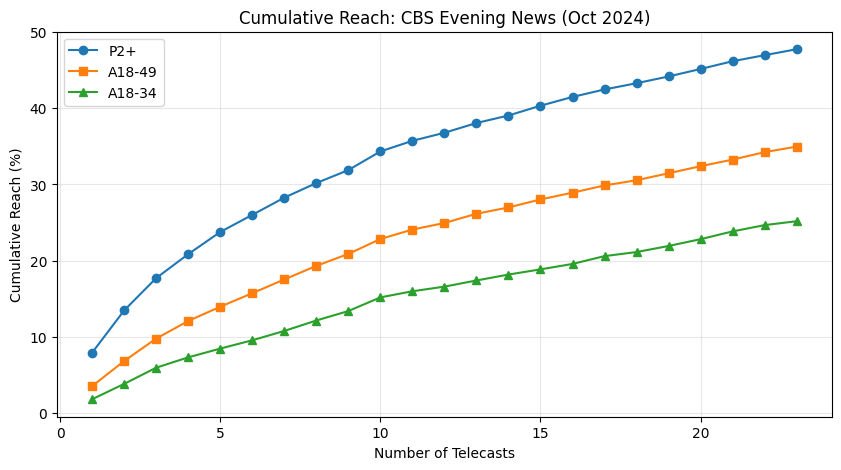

Telecasts of the program: 23
Average household rating (%): 17.3
Average P2+ rating (%): 8.6
Average projected audience (M): 27.29
Final reach P2+ (%): 47.8
Final reach A18-34 (%): 25.2
Final reach A18-49 (%): 35.0


In [15]:
# 1. Filter for "CBS Evening News" in October
cbs_news = programs[(programs['program_name'] == 'CBS Evening News') &
                    (programs['network_code'] == 'CBS')].sort_values('broadcast_date')

# Pre-calculate ages for demographic filtering (Age is attr_id 300)
age_df = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})
age_dict = age_df.set_index('respondent_id')['age'].to_dict()

# Pre-calculate average monthly weights for reach calculation
monthly_weights = daily_weights.groupby(['respondent_id', 'resp_type'])['weight'].mean().reset_index()
monthly_weights = monthly_weights.merge(age_df, on='respondent_id', how='left')
monthly_w_dict = monthly_weights.set_index('respondent_id')['weight'].to_dict()

# Universe sizes for reach (sum of average monthly weights for each group)
univ_reach_p2 = monthly_weights[monthly_weights['resp_type'].isin(['R', 'L'])]['weight'].sum()
univ_reach_18_34 = monthly_weights[(monthly_weights['resp_type'].isin(['R', 'L'])) & (monthly_weights['age'] >= 18) & (monthly_weights['age'] <= 34)]['weight'].sum()
univ_reach_18_49 = monthly_weights[(monthly_weights['resp_type'].isin(['R', 'L'])) & (monthly_weights['age'] >= 18) & (monthly_weights['age'] <= 49)]['weight'].sum()

# Tracking variables
reached_p2 = set()
reached_18_34 = set()
reached_18_49 = set()

reach_curve_p2 = []
reach_curve_18_34 = []
reach_curve_18_49 = []

ratings_hh = []
ratings_p2 = []
audiences_m = []

# Index daily weights for fast daily lookups during the loop
daily_w_indexed = daily_weights.set_index(['broadcast_date', 'respondent_id'])

# Table header
print(f"{'Date':<15} | {'HH Rating %':<15} | {'P2+ Rating %':<15} | {'Proj Aud (M)':<15}")
print("-" * 65)

for _, tcast in cbs_news.iterrows():
    tcast_start = tcast['start_ts']
    tcast_end = tcast['end_ts']
    b_date = tcast['broadcast_date']

    # Find viewings that overlap with the telecast
    v = viewings[(viewings['start_ts'] < tcast_end) & (viewings['end_ts'] > tcast_start)].copy()

    # Calculate exact overlap duration in minutes
    v['overlap_start'] = v['start_ts'].clip(lower=tcast_start)
    v['overlap_end'] = v['end_ts'].clip(upper=tcast_end)
    v['overlap_min'] = (v['overlap_end'] - v['overlap_start']).dt.total_seconds() / 60.0

    # Rule: watched at least 1 minute
    valid_v = v[v['overlap_min'] >= 1.0]

    watched_hh = valid_v[valid_v['resp_type'] == 'H']['respondent_id'].unique()
    watched_p2 = valid_v[valid_v['resp_type'].isin(['R', 'L'])]['respondent_id'].unique()

    # Calculate Ratings
    if b_date in daily_w_indexed.index.levels[0]:
        day_weights = daily_w_indexed.loc[b_date]

        in_tab_hh = day_weights[day_weights['resp_type'] == 'H']['weight'].sum()
        in_tab_p2 = day_weights[day_weights['resp_type'].isin(['R', 'L'])]['weight'].sum()

        aud_hh = day_weights.reindex(watched_hh)['weight'].sum()
        aud_p2 = day_weights.reindex(watched_p2)['weight'].sum()

        r_hh = (aud_hh / in_tab_hh * 100) if in_tab_hh > 0 else 0
        r_p2 = (aud_p2 / in_tab_p2 * 100) if in_tab_p2 > 0 else 0
        aud_m = aud_p2 / 1_000_000
    else:
        r_hh, r_p2, aud_m = 0, 0, 0

    ratings_hh.append(r_hh)
    ratings_p2.append(r_p2)
    audiences_m.append(aud_m)

    # Print row for the table
    print(f"{str(b_date):<15} | {r_hh:<15.2f} | {r_p2:<15.2f} | {aud_m:<15.2f}")

    # Calculate Reach (Cumulative)
    reached_p2.update(watched_p2)
    for rid in watched_p2:
        age = age_dict.get(rid, -1)
        if 18 <= age <= 34:
            reached_18_34.add(rid)
        if 18 <= age <= 49:
            reached_18_49.add(rid)

    reach_w_p2 = sum(monthly_w_dict.get(rid, 0) for rid in reached_p2)
    reach_w_18_34 = sum(monthly_w_dict.get(rid, 0) for rid in reached_18_34)
    reach_w_18_49 = sum(monthly_w_dict.get(rid, 0) for rid in reached_18_49)

    reach_curve_p2.append((reach_w_p2 / univ_reach_p2 * 100) if univ_reach_p2 > 0 else 0)
    reach_curve_18_34.append((reach_w_18_34 / univ_reach_18_34 * 100) if univ_reach_18_34 > 0 else 0)
    reach_curve_18_49.append((reach_w_18_49 / univ_reach_18_49 * 100) if univ_reach_18_49 > 0 else 0)

# Averages
avg_r_hh = sum(ratings_hh) / len(ratings_hh)
avg_r_p2 = sum(ratings_p2) / len(ratings_p2)
avg_aud_m = sum(audiences_m) / len(audiences_m)

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cbs_news) + 1), reach_curve_p2, label='P2+', marker='o')
plt.plot(range(1, len(cbs_news) + 1), reach_curve_18_49, label='A18-49', marker='s')
plt.plot(range(1, len(cbs_news) + 1), reach_curve_18_34, label='A18-34', marker='^')
plt.title('Cumulative Reach: CBS Evening News (Oct 2024)')
plt.xlabel('Number of Telecasts')
plt.ylabel('Cumulative Reach (%)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("Telecasts of the program:", len(cbs_news))
print("Average household rating (%):", round(avg_r_hh, 1))
print("Average P2+ rating (%):", round(avg_r_p2, 1))
print("Average projected audience (M):", round(avg_aud_m, 2))
print("Final reach P2+ (%):", round(reach_curve_p2[-1], 1))
print("Final reach A18-34 (%):", round(reach_curve_18_34[-1], 1))
print("Final reach A18-49 (%):", round(reach_curve_18_49[-1], 1))

**Answer:** Cumulative reach keeps growing because of audience churn: the exact same people do not watch the news every single day. As new unique viewers tune in sporadically over the month, they add to the total unduplicated reach, while the daily rating (the average audience size for a single telecast) remains relatively stable.
The program reaches the P2+ audience significantly better than the younger demographics (A18-34 and A18-49). This perfectly matches the well-known industry trend that traditional broadcast network evening news heavily skews toward older viewers.

## Task 3 — Program frequency

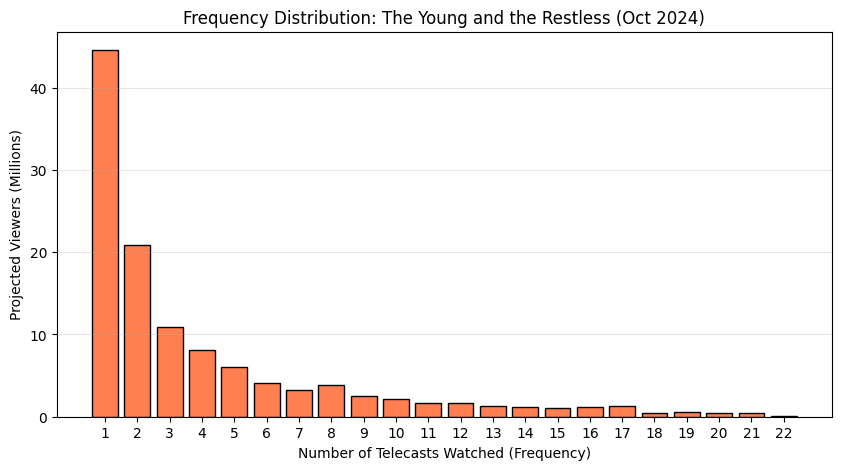

Projected viewers (M): 117.93
Average frequency (weighted): 4.0
Median frequency (weighted): 2
Share of views from the most loyal viewers: 0.617


In [16]:
# Filter for "The Young and the Restless" on CBS
yr_tcasts = programs[(programs['program_name'] == 'The Young and the Restless') &
                     (programs['network_code'] == 'CBS')]

# Track frequency (number of telecasts watched) per viewer
viewer_freq = {}

for _, tcast in yr_tcasts.iterrows():
    tcast_start = tcast['start_ts']
    tcast_end = tcast['end_ts']

    # Overlapping viewings
    v = viewings[(viewings['start_ts'] < tcast_end) & (viewings['end_ts'] > tcast_start)].copy()
    v['overlap_start'] = v['start_ts'].clip(lower=tcast_start)
    v['overlap_end'] = v['end_ts'].clip(upper=tcast_end)
    v['overlap_min'] = (v['overlap_end'] - v['overlap_start']).dt.total_seconds() / 60.0

    # Rule: watched at least 1 minute and only persons (R, L)
    valid_v = v[(v['overlap_min'] >= 1.0) & (v['resp_type'].isin(['R', 'L']))]

    for rid in valid_v['respondent_id'].unique():
        viewer_freq[rid] = viewer_freq.get(rid, 0) + 1

# Create DataFrame from frequency dict
freq_df = pd.DataFrame(list(viewer_freq.items()), columns=['respondent_id', 'frequency'])

# Calculate monthly average weights for persons
monthly_weights_p2 = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].groupby('respondent_id')['weight'].mean()
freq_df['weight'] = freq_df['respondent_id'].map(monthly_weights_p2).fillna(0)

# Calculations
proj_viewers_m = freq_df['weight'].sum() / 1_000_000

total_views = (freq_df['frequency'] * freq_df['weight']).sum()
avg_freq = total_views / freq_df['weight'].sum()

# Weighted median and percentiles
freq_df_sorted = freq_df.sort_values('frequency')
freq_df_sorted['cum_weight'] = freq_df_sorted['weight'].cumsum()
total_w = freq_df['weight'].sum()

median_freq = freq_df_sorted[freq_df_sorted['cum_weight'] >= total_w / 2]['frequency'].iloc[0]

# 80th percentile of frequency
p80_freq = freq_df_sorted[freq_df_sorted['cum_weight'] >= total_w * 0.8]['frequency'].iloc[0]

# Loyal viewers (frequency >= 80th percentile)
loyal_df = freq_df[freq_df['frequency'] >= p80_freq]
loyal_views = (loyal_df['frequency'] * loyal_df['weight']).sum()
loyal_share = loyal_views / total_views

# Plotting the frequency distribution
freq_dist = freq_df.groupby('frequency')['weight'].sum() / 1_000_000

plt.figure(figsize=(10, 5))
plt.bar(freq_dist.index, freq_dist.values, color='coral', edgecolor='black')
plt.title('Frequency Distribution: The Young and the Restless (Oct 2024)')
plt.xlabel('Number of Telecasts Watched (Frequency)')
plt.ylabel('Projected Viewers (Millions)')
plt.xticks(range(1, int(freq_df['frequency'].max()) + 1))
plt.grid(axis='y', alpha=0.3)
plt.show()

print("Projected viewers (M):", round(proj_viewers_m, 2))
print("Average frequency (weighted):", round(avg_freq, 1))
print("Median frequency (weighted):", round(median_freq, 1))
print("Share of views from the most loyal viewers:", round(loyal_share, 3))

**Answer:** The average frequency is not a fair summary of the audience's viewing behavior ("the average can lie"). As seen in the distribution chart, the audience is highly polarized: a large mass of casual viewers watched only 1 or 2 episodes, while a smaller but deeply dedicated core of loyal viewers watched almost every single episode in the month. The average falls somewhere in the middle, implying a "typical" viewer watched a moderate amount, when in reality, almost no one in the audience actually behaves that way.

## Task 4 — Networks by age and gender

In [17]:
# Create a mapping for Age and Sex
age_df = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})
age_dict = age_df.set_index('respondent_id')['age'].to_dict()

# Sex codes: 201 (Male), 202 (Female)
sex_df = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])][['respondent_id', 'attr_id']]
sex_df['sex'] = sex_df['attr_id'].map({201: 'M', 202: 'W'})
sex_dict = sex_df.set_index('respondent_id')['sex'].to_dict()

# Base dataset for persons viewing
v_persons = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
v_persons['duration_min'] = (v_persons['end_ts'] - v_persons['start_ts']).dt.total_seconds() / 60.0
v_persons['proj_minutes'] = v_persons['duration_min'] * v_persons['weight']

# Map attributes
v_persons['age'] = v_persons['respondent_id'].map(age_dict)
v_persons['sex'] = v_persons['respondent_id'].map(sex_dict)

# Function to assign demographic group
def get_demo_group(row):
    s = row['sex']
    a = row['age']
    if pd.isna(s) or pd.isna(a): return 'Other'

    if 18 <= a <= 34: return f"{s}18-34"
    if 35 <= a <= 54: return f"{s}35-54"
    if a >= 55:       return f"{s}55+"
    return 'Other'

v_persons['demo'] = v_persons.apply(get_demo_group, axis=1)

demos_to_analyze = ['M18-34', 'W18-34', 'M35-54', 'W35-54', 'M55+', 'W55+']

# Print Top 5 networks for each demographic
for demo in demos_to_analyze:
    demo_df = v_persons[v_persons['demo'] == demo]
    top_5 = demo_df.groupby('network_code')['proj_minutes'].sum().nlargest(5)

    print(f"\n--- Top 5 Networks for {demo} ---")
    for i, (net, mins) in enumerate(top_5.items(), 1):
        print(f"{i}. {net} ({mins / 1_000_000_000:.2f}B projected minutes)")

# Calculate youngest and oldest network (share of 18-34)
# Combine M18-34 and W18-34
v_persons['is_18_34'] = v_persons['demo'].isin(['M18-34', 'W18-34'])

# Weighted (projected) metrics
net_total_proj = v_persons.groupby('network_code')['proj_minutes'].sum()
net_1834_proj = v_persons[v_persons['is_18_34']].groupby('network_code')['proj_minutes'].sum()
share_1834_weighted = (net_1834_proj / net_total_proj).fillna(0)

# Raw (unweighted panel) metrics
net_total_raw = v_persons.groupby('network_code')['duration_min'].sum()
net_1834_raw = v_persons[v_persons['is_18_34']].groupby('network_code')['duration_min'].sum()
share_1834_raw = (net_1834_raw / net_total_raw).fillna(0)

youngest_network = share_1834_weighted.idxmax()
oldest_network = share_1834_weighted.idxmin()

# Print the comparison table
print("\n" + "="*50)
print(f"{'Network':<10} | {'Weighted 18-34 Share':<20} | {'Raw 18-34 Share':<15}")
print("-" * 50)
for net in share_1834_weighted.index:
    print(f"{net:<10} | {share_1834_weighted[net]:<20.3f} | {share_1834_raw[net]:<15.3f}")
print("="*50 + "\n")

print("Youngest network:", youngest_network)
print("Oldest network:", oldest_network)


--- Top 5 Networks for M18-34 ---
1. FOX (4.39B projected minutes)
2. NBC (3.91B projected minutes)
3. CBS (3.04B projected minutes)
4. ABC (3.01B projected minutes)
5. FX (1.47B projected minutes)

--- Top 5 Networks for W18-34 ---
1. FOX (4.57B projected minutes)
2. NBC (4.53B projected minutes)
3. ABC (3.50B projected minutes)
4. CBS (2.81B projected minutes)
5. FX (1.38B projected minutes)

--- Top 5 Networks for M35-54 ---
1. FOX (12.80B projected minutes)
2. NBC (10.99B projected minutes)
3. ABC (9.04B projected minutes)
4. CBS (8.13B projected minutes)
5. FX (2.37B projected minutes)

--- Top 5 Networks for W35-54 ---
1. NBC (11.64B projected minutes)
2. FOX (11.16B projected minutes)
3. ABC (9.44B projected minutes)
4. CBS (8.16B projected minutes)
5. HGTV (3.05B projected minutes)

--- Top 5 Networks for M55+ ---
1. CBS (38.27B projected minutes)
2. NBC (34.27B projected minutes)
3. FOX (30.88B projected minutes)
4. ABC (30.79B projected minutes)
5. FNC (27.90B projected minu

**Answer:** The weighted shares are noticeably different (higher) than the raw panel shares. This tells us that younger adults (18-34) are under-represented in the raw panel (they are likely harder to recruit or keep active with people meters). The weighting process corrects this by assigning higher weights to the young people who *are* in the panel so they properly represent their true proportion in the US universe. If we reported raw numbers to a client, we would severely underestimate the size and importance of the young adult audience for these networks.

**Bonus answer:** If I were selling ads on the oldest network (Fox News) to an advertiser who wants young adults, I would pitch the absolute scale of the audience. Even if young adults make up a tiny *percentage* of our total viewership, the sheer massive size of our total audience means we still deliver a very large *absolute number* of young viewers—potentially more than a small niche network that skews 100% young. Plus, because our average viewer is older, we might be able to offer those young eyeballs at a much cheaper CPM (Cost Per Thousand) than a premium youth-focused network.